# SyncCare - Model Benchmark

This notebook reports the performance of the two model families after hyperparameter tuning.

Only post-tuning results are used for model comparison.

The evaluation pipeline is:

1. Patient-level 80/20 train-test split
2. Hyperparameter tuning using grouped cross-validation
3. Selection of the best hyperparameter configuration for each model
4. Full 80% training-set grouped cross-validation for both tuned models
5. Comparison using Macro F1
6. Selection of the final model
7. Final training on the complete 80% training partition
8. Evaluation on the locked 20% patient-level test set

The earlier untuned Decision Tree baseline is intentionally excluded.

In [38]:
# Imports and configuration

import os
import joblib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RESULTS_DIR = "../results"
MODEL_DIR = "../model"

print("Benchmark environment ready.")

Benchmark environment ready.


## 1. Load Post-Tuning Model Comparison

The model comparison below contains the best hyperparameter configuration for each model family, revalidated using the complete 80% training partition with patient-level grouped cross-validation.

These are the only Decision Tree and Random Forest metrics used for model-family comparison.

In [39]:
# Load full-training CV comparison

TUNED_COMPARISON_PATH = os.path.join(
    RESULTS_DIR,
    "tuned_model_comparison.csv"
)

tuned_comparison = pd.read_csv(
    TUNED_COMPARISON_PATH
)

display(
    tuned_comparison.style.format({
        "Accuracy": "{:.2%}",
        "Macro Precision": "{:.2%}",
        "Macro Recall": "{:.2%}",
        "Macro F1": "{:.2%}",
        "CV Time (seconds)": "{:.2f}"
    })
)

,Model,Parameters,Accuracy,Macro Precision,Macro Recall,Macro F1,CV Time (seconds)
0,Random Forest,"{'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 2, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 150, 'n_jobs': -1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}",95.32%,95.51%,95.49%,95.49%,834.65
1,Decision Tree,"{'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'entropy', 'max_depth': 30, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 10, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 42, 'splitter': 'best'}",95.28%,95.47%,95.46%,95.46%,75.36


## 2. Post-Tuning Model Comparison

Both model families are compared using the same evaluation procedure:

- Same patient-level 80% training partition
- Same 3-fold StratifiedGroupKFold
- Same patient grouping
- Same disease stratification
- Best hyperparameters selected through tuning
- Macro F1 used as the primary selection metric

No pre-tuning baseline result is included.

In [40]:
# Identify the two tuned model results

dt_result = tuned_comparison[
    tuned_comparison["Model"] == "Decision Tree"
].iloc[0]

rf_result = tuned_comparison[
    tuned_comparison["Model"] == "Random Forest"
].iloc[0]

print("Tuned Decision Tree")
print("-------------------")
print(f"Accuracy : {dt_result['Accuracy']:.4f}")
print(f"Precision: {dt_result['Macro Precision']:.4f}")
print(f"Recall   : {dt_result['Macro Recall']:.4f}")
print(f"Macro F1 : {dt_result['Macro F1']:.4f}")

print("\nTuned Random Forest")
print("-------------------")
print(f"Accuracy : {rf_result['Accuracy']:.4f}")
print(f"Precision: {rf_result['Macro Precision']:.4f}")
print(f"Recall   : {rf_result['Macro Recall']:.4f}")
print(f"Macro F1 : {rf_result['Macro F1']:.4f}")

Tuned Decision Tree
-------------------
Accuracy : 0.9528
Precision: 0.9547
Recall   : 0.9546
Macro F1 : 0.9546

Tuned Random Forest
-------------------
Accuracy : 0.9532
Precision: 0.9551
Recall   : 0.9549
Macro F1 : 0.9549


## 3. Tuned Model Performance Table

In [41]:
# Clean comparison table

benchmark = tuned_comparison[
    [
        "Model",
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1"
    ]
].copy()

display(
    benchmark.style.format({
        "Accuracy": "{:.2%}",
        "Macro Precision": "{:.2%}",
        "Macro Recall": "{:.2%}",
        "Macro F1": "{:.2%}"
    })
)

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Random Forest,95.32%,95.51%,95.49%,95.49%
1,Decision Tree,95.28%,95.47%,95.46%,95.46%


## 4. Difference Between Tuned Models

The difference is calculated only between the two post-tuning full-training CV results.

No untuned baseline is used.

In [42]:
# Calculate difference between tuned models

metrics = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1"
]

advantage_rows = []

for metric in metrics:

    difference = (
        rf_result[metric]
        - dt_result[metric]
    ) * 100

    advantage_rows.append({
        "Metric": metric,
        "Decision Tree (%)": dt_result[metric] * 100,
        "Random Forest (%)": rf_result[metric] * 100,
        "RF - DT (percentage points)": difference
    })

advantage = pd.DataFrame(
    advantage_rows
).round(2)

display(advantage)

,Metric,Decision Tree (%),Random Forest (%),RF - DT (percentage points)
0,Accuracy,95.28,95.32,0.04
1,Macro Precision,95.47,95.51,0.04
2,Macro Recall,95.46,95.49,0.03
3,Macro F1,95.46,95.49,0.04


## 5. Accuracy Comparison

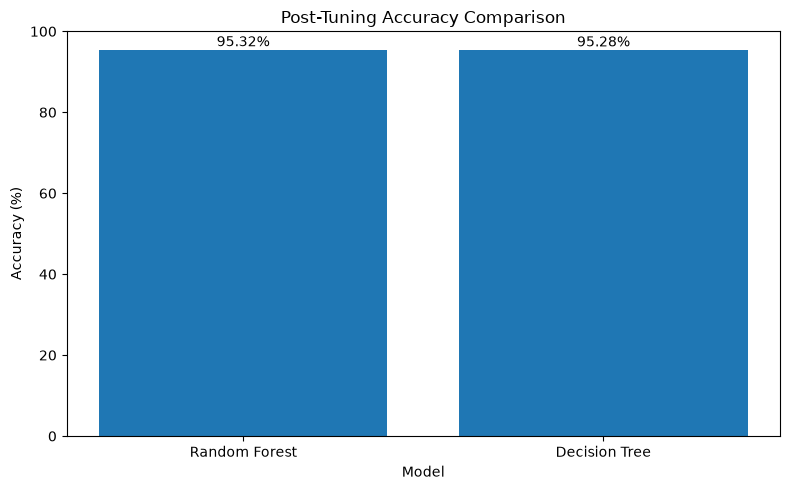

Saved: ../results/tuned_accuracy_comparison.png


In [43]:
# Accuracy comparison

plt.figure(figsize=(8, 5))

bars = plt.bar(
    benchmark["Model"],
    benchmark["Accuracy"] * 100
)

plt.ylabel("Accuracy (%)")
plt.xlabel("Model")
plt.title("Post-Tuning Accuracy Comparison")
plt.ylim(0, 100)

for bar in bars:

    value = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()

accuracy_plot_path = os.path.join(
    RESULTS_DIR,
    "tuned_accuracy_comparison.png"
)

plt.savefig(
    accuracy_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", accuracy_plot_path)

## 6. Comprehensive Classification Metrics

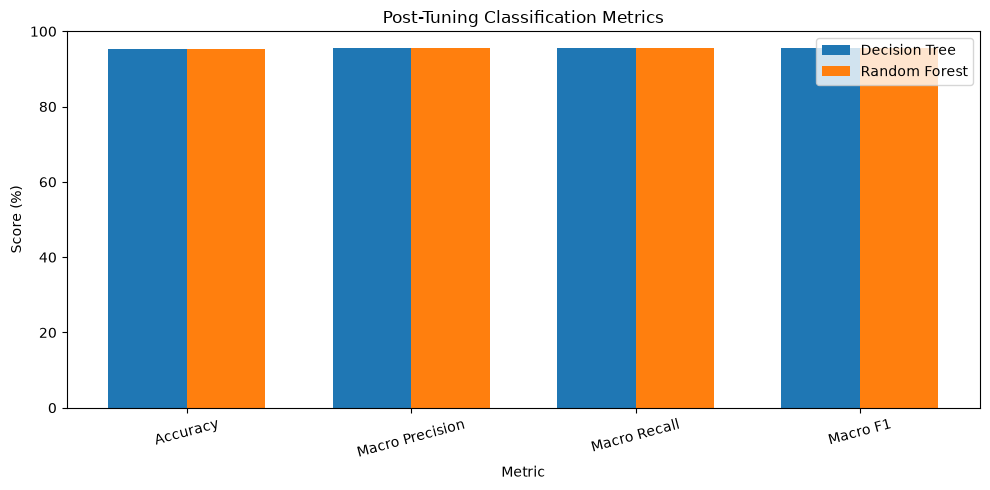

Saved: ../results/tuned_classification_metrics.png


In [44]:
# Multi-metric comparison

metrics = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1"
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(
    x - width / 2,
    benchmark.iloc[0][metrics].values * 100,
    width,
    label="Decision Tree"
)

plt.bar(
    x + width / 2,
    benchmark.iloc[1][metrics].values * 100,
    width,
    label="Random Forest"
)

plt.xticks(
    x,
    metrics,
    rotation=15
)

plt.ylabel("Score (%)")
plt.xlabel("Metric")
plt.title("Post-Tuning Classification Metrics")
plt.ylim(0, 100)
plt.legend()

plt.tight_layout()

metrics_plot_path = os.path.join(
    RESULTS_DIR,
    "tuned_classification_metrics.png"
)

plt.savefig(
    metrics_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", metrics_plot_path)

## 7. Final Model Locked-Test Performance

The model selected from the full-training grouped CV comparison was subsequently trained on the complete 80% training partition.

Its performance below comes from the untouched 20% patient-level locked test set.

This is separate from the model-family comparison above.

In [45]:
# Load final locked-test result

FINAL_RESULTS_PATH = os.path.join(
    RESULTS_DIR,
    "model_results.csv"
)

final_results = pd.read_csv(
    FINAL_RESULTS_PATH
)

display(
    final_results.style.format({
        "accuracy": "{:.2%}",
        "precision_macro": "{:.2%}",
        "recall_macro": "{:.2%}",
        "f1_macro": "{:.2%}",
        "training_time_seconds": "{:.2f}",
        "prediction_time_seconds": "{:.2f}"
    })
)

,model,accuracy,precision_macro,recall_macro,f1_macro,training_time_seconds,prediction_time_seconds
0,Random Forest,95.32%,95.51%,95.50%,95.50%,497.87,8.97


## 8. Final Confusion Matrix

The confusion matrix below was generated from the final model's predictions on the locked patient-level test set.

Rows represent the true disease class and columns represent the predicted disease class.

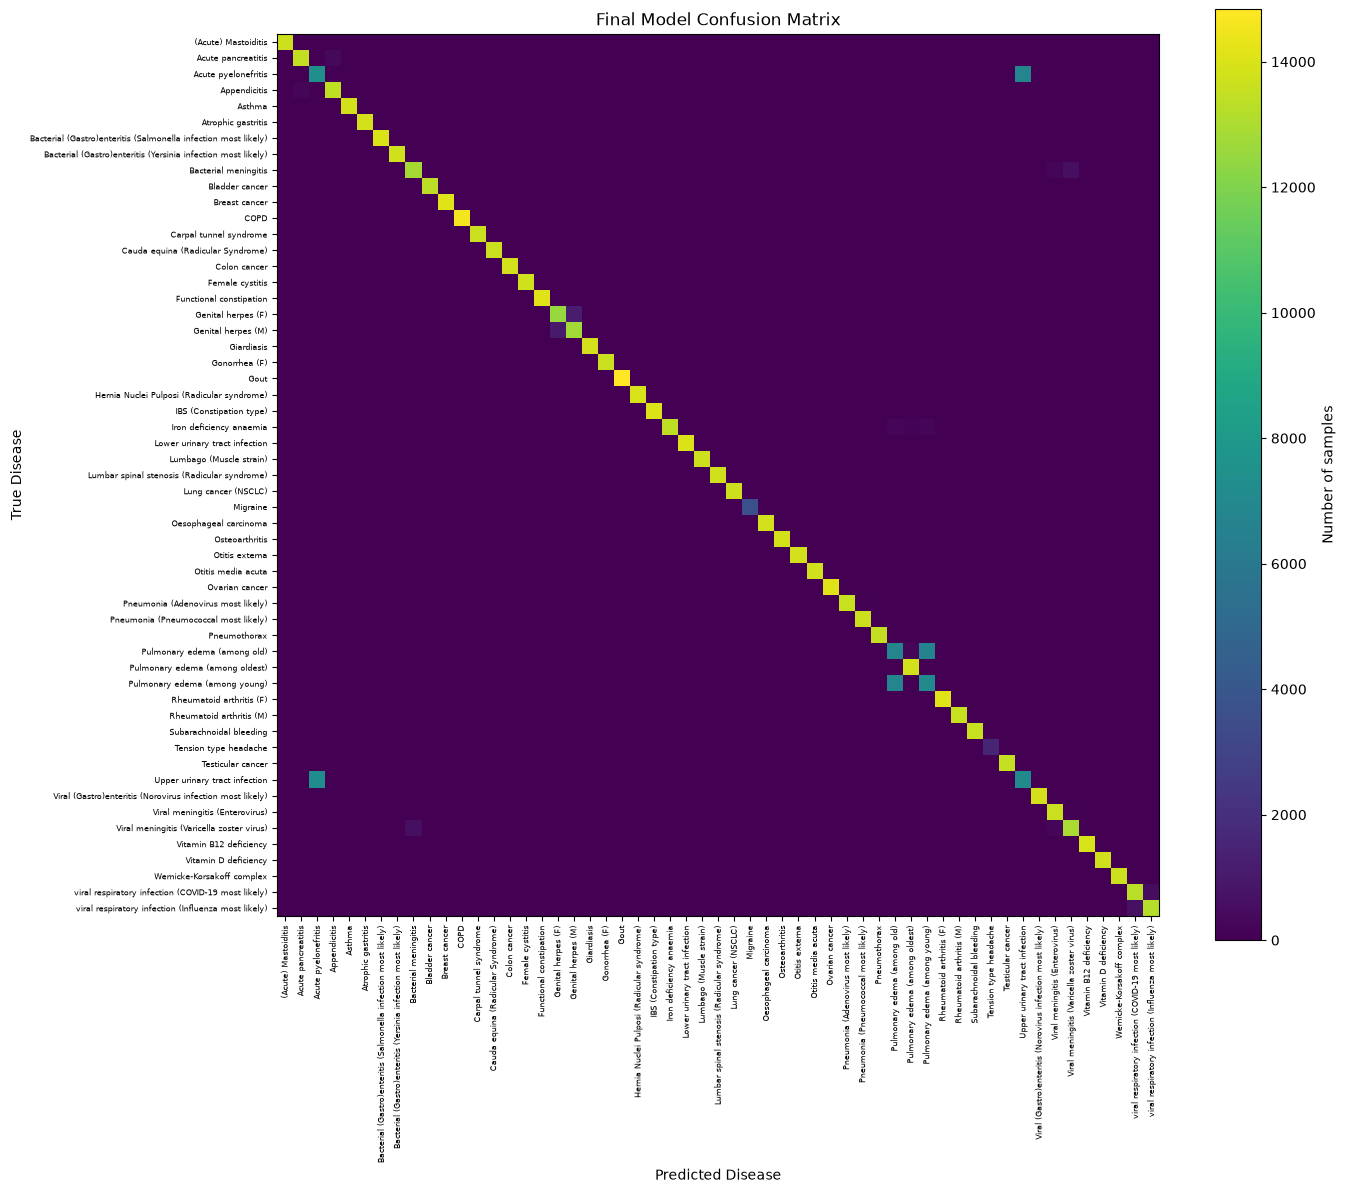

Saved: ../results/final_confusion_matrix.png


In [46]:
# Load and visualize final confusion matrix

CM_PATH = os.path.join(
    RESULTS_DIR,
    "confusion_matrix.csv"
)

cm_df = pd.read_csv(
    CM_PATH,
    index_col=0
)

cm = cm_df.values
labels = cm_df.index.tolist()

plt.figure(figsize=(14, 12))

plt.imshow(cm)

plt.colorbar(
    label="Number of samples"
)

plt.xticks(
    np.arange(len(labels)),
    labels,
    rotation=90,
    fontsize=6
)

plt.yticks(
    np.arange(len(labels)),
    labels,
    fontsize=6
)

plt.xlabel("Predicted Disease")
plt.ylabel("True Disease")
plt.title("Final Model Confusion Matrix")

plt.tight_layout()

cm_plot_path = os.path.join(
    RESULTS_DIR,
    "final_confusion_matrix.png"
)

plt.savefig(
    cm_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", cm_plot_path)

## 9. Final Model Summary

The final model is selected strictly from the post-tuning full-training grouped cross-validation results.

The earlier untuned Decision Tree result is not used anywhere in this benchmark.

The locked-test metrics describe the performance of the selected final model on previously unseen patients.

In [47]:
# Final benchmark summary and export

selected_model_name = final_results.iloc[0]["model"]

print("=" * 55)
print("SYNC CARE - FINAL MODEL BENCHMARK")
print("=" * 55)

print("\nPost-tuning CV comparison:")
display(
    benchmark.style.format({
        "Accuracy": "{:.2%}",
        "Macro Precision": "{:.2%}",
        "Macro Recall": "{:.2%}",
        "Macro F1": "{:.2%}"
    })
)

print("\nSelected final model:", selected_model_name)

print("\nLocked-test performance:")
print(
    f"Accuracy        : "
    f"{final_results.iloc[0]['accuracy']:.4f}"
)

print(
    f"Macro Precision : "
    f"{final_results.iloc[0]['precision_macro']:.4f}"
)

print(
    f"Macro Recall    : "
    f"{final_results.iloc[0]['recall_macro']:.4f}"
)

print(
    f"Macro F1        : "
    f"{final_results.iloc[0]['f1_macro']:.4f}"
)

# Save benchmark comparison
benchmark_path = os.path.join(
    RESULTS_DIR,
    "model_benchmark.csv"
)

benchmark.to_csv(
    benchmark_path,
    index=False
)

# Save tuned-model differences
advantage_path = os.path.join(
    RESULTS_DIR,
    "model_advantage.csv"
)

advantage.to_csv(
    advantage_path,
    index=False
)

print("\nSaved:")
print(benchmark_path)
print(advantage_path)

print("\nBenchmark complete.")

SYNC CARE - FINAL MODEL BENCHMARK

Post-tuning CV comparison:


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Random Forest,95.32%,95.51%,95.49%,95.49%
1,Decision Tree,95.28%,95.47%,95.46%,95.46%



Selected final model: Random Forest

Locked-test performance:
Accuracy        : 0.9532
Macro Precision : 0.9551
Macro Recall    : 0.9550
Macro F1        : 0.9550

Saved:
../results/model_benchmark.csv
../results/model_advantage.csv

Benchmark complete.
